# 02 · Regresión multivariable y normalización

Semana 2. Datos sintéticos de pisos: superficie (m²), habitaciones, antigüedad (años) → precio (miles de €).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 4)

In [2]:
m = 200
area = np.random.uniform(40, 160, m)
rooms = np.random.randint(1, 6, m).astype(float)
age = np.random.uniform(0, 60, m)
X = np.column_stack([area, rooms, age])
y = 2.2 * area + 12 * rooms - 0.9 * age + 40 + np.random.normal(0, 15, m)
print(X[:3]); print("rangos:", X.min(0), X.max(0))

[[105.85762047   3.          18.40860597]
 [125.82272396   5.          34.65257693]
 [112.33160513   4.          57.56600045]]
rangos: [40.56345714  1.          0.16219283] [159.86164079   5.          59.66404738]


## 1. Funciones vectorizadas

In [3]:
def compute_cost(X, y, w, b):
    err = X @ w + b - y
    return (err @ err) / (2 * X.shape[0])

def compute_gradient(X, y, w, b):
    m = X.shape[0]
    err = X @ w + b - y
    return X.T @ err / m, err.mean()

def gradient_descent(X, y, w, b, alpha, iters):
    hist = []
    for _ in range(iters):
        dw, db = compute_gradient(X, y, w, b)
        w, b = w - alpha * dw, b - alpha * db
        hist.append(compute_cost(X, y, w, b))
    return w, b, hist

## 2. Sin normalizar

In [4]:
w0 = np.zeros(3)
for alpha in [1e-4, 3e-4]:
    _, _, h = gradient_descent(X, y, w0, 0.0, alpha, 300)
    print(f"α={alpha}: J final = {h[-1]:.3g}  ({'diverge' if not np.isfinite(h[-1]) or h[-1] > h[0] else 'baja'})")

α=0.0001: J final = 361  (baja)
α=0.0003: J final = 4.17e+253  (diverge)


## 3. Z-score
$x_j \leftarrow (x_j-\mu_j)/\sigma_j$ — guarda μ y σ para normalizar datos nuevos.

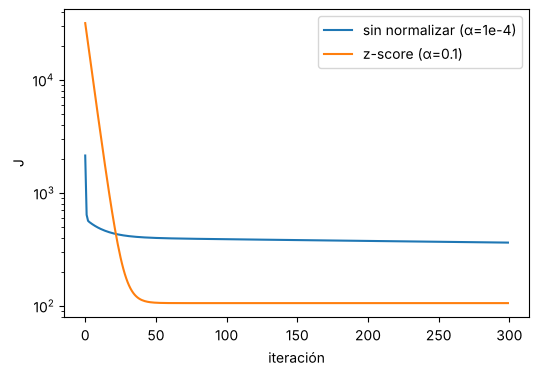

w (escala normalizada): [ 76.19  15.54 -14.87]  b: 267.49


In [5]:
def zscore_fit(X):
    return X.mean(axis=0), X.std(axis=0)

def zscore_apply(X, mu, sigma):
    return (X - mu) / sigma

mu, sigma = zscore_fit(X)
Xn = zscore_apply(X, mu, sigma)
wn, bn, hn = gradient_descent(Xn, y, np.zeros(3), 0.0, alpha=0.1, iters=300)
_, _, h_raw = gradient_descent(X, y, np.zeros(3), 0.0, alpha=1e-4, iters=300)
plt.plot(h_raw, label="sin normalizar (α=1e-4)"); plt.plot(hn, label="z-score (α=0.1)")
plt.yscale("log"); plt.legend(); plt.xlabel("iteración"); plt.ylabel("J"); plt.show()
print("w (escala normalizada):", wn.round(2), " b:", round(bn, 2))

## 4. Recuperar los coeficientes en unidades originales y comparar con la ecuación normal

In [6]:
w_orig = wn / sigma
b_orig = bn - (wn * mu / sigma).sum()
Xb = np.column_stack([np.ones(m), X])
theta = np.linalg.lstsq(Xb, y, rcond=None)[0]
print("descenso de gradiente:", w_orig.round(3), round(b_orig, 2))
print("mínimos cuadrados    :", theta[1:].round(3), round(theta[0], 2))
print("valores reales       : [2.2, 12, -0.9] 40")

descenso de gradiente: [ 2.236 10.752 -0.845] 36.58
mínimos cuadrados    : [ 2.236 10.752 -0.845] 36.58
valores reales       : [2.2, 12, -0.9] 40


## 5. Predicción para un piso nuevo (¡normalizando con μ, σ del entrenamiento!)

In [7]:
nuevo = np.array([[90, 3, 20]])
print(f"precio estimado: {(zscore_apply(nuevo, mu, sigma) @ wn + bn)[0]:.1f} k€")

precio estimado: 253.2 k€


## 6. Regresión polinómica
Características $x, x^2, x^3$: el modelo sigue siendo lineal en los parámetros. Sin escalar, $x^3$ domina.

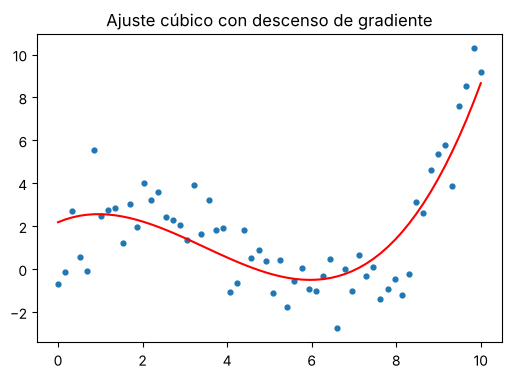

In [8]:
xp = np.linspace(0, 10, 60)
yp = 0.08 * xp**3 - xp**2 + 3 * xp + np.random.normal(0, 1.2, xp.size)
F = np.column_stack([xp, xp**2, xp**3])
mu_p, s_p = zscore_fit(F)
wp, bp, _ = gradient_descent(zscore_apply(F, mu_p, s_p), yp, np.zeros(3), 0.0, 0.1, 5000)
plt.scatter(xp, yp, s=12); plt.plot(xp, zscore_apply(F, mu_p, s_p) @ wp + bp, "r"); plt.title("Ajuste cúbico con descenso de gradiente"); plt.show()